<a href="https://colab.research.google.com/github/aparnnar25/loan-assignment/blob/main/loan_(6).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from google.colab import drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Libraries and packages

In [7]:
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import LabelEncoder, StandardScaler,OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import SMOTE
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report,roc_auc_score,roc_curve

# **DATA**  **lOADING**

In [8]:
df = pd.read_csv("/content/drive/MyDrive/ICT/loan.csv")

In [9]:
# Displaying first 5 data

df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


#  **To** **check** **the** **missing** **value** **of** **each** **column**

In [10]:
df.isna().sum()

,0
Loan_ID,0
Gender,13
Married,3
Dependents,15
Education,0
Self_Employed,32
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,22
Loan_Amount_Term,14


In [11]:
# Datatypes
df.dtypes

,0
Loan_ID,object
Gender,object
Married,object
Dependents,object
Education,object
Self_Employed,object
ApplicantIncome,int64
CoapplicantIncome,float64
LoanAmount,float64
Loan_Amount_Term,float64


In [12]:
df.tail()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
609,LP002978,Female,No,0,Graduate,No,2900,0.0,71.0,360.0,1.0,Rural,Y
610,LP002979,Male,Yes,3+,Graduate,No,4106,0.0,40.0,180.0,1.0,Rural,Y
611,LP002983,Male,Yes,1,Graduate,No,8072,240.0,253.0,360.0,1.0,Urban,Y
612,LP002984,Male,Yes,2,Graduate,No,7583,0.0,187.0,360.0,1.0,Urban,Y
613,LP002990,Female,No,0,Graduate,Yes,4583,0.0,133.0,360.0,0.0,Semiurban,N


In [13]:
from sklearn.impute import KNNImputer

In [14]:
km =  KNNImputer(n_neighbors=5)

In [15]:
df_numerical = df.select_dtypes(exclude=["object"])


In [16]:
imdata = km.fit_transform(df_numerical)

In [17]:
imdata

array([[5.849e+03, 0.000e+00, 1.478e+02, 3.600e+02, 1.000e+00],
       [4.583e+03, 1.508e+03, 1.280e+02, 3.600e+02, 1.000e+00],
       [3.000e+03, 0.000e+00, 6.600e+01, 3.600e+02, 1.000e+00],
       ...,
       [8.072e+03, 2.400e+02, 2.530e+02, 3.600e+02, 1.000e+00],
       [7.583e+03, 0.000e+00, 1.870e+02, 3.600e+02, 1.000e+00],
       [4.583e+03, 0.000e+00, 1.330e+02, 3.600e+02, 0.000e+00]])

In [18]:

df_imdata = pd.DataFrame(data=imdata , columns=df_numerical.columns)

In [19]:
df_imdata.head(2)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
0,5849.0,0.0,147.8,360.0,1.0
1,4583.0,1508.0,128.0,360.0,1.0


In [20]:
df_imdata.isna().sum()

,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [21]:
from sklearn.impute import SimpleImputer  # we use this for catagorical value

In [22]:
df_categories = df.select_dtypes(include=["object"])

In [23]:
sm =  SimpleImputer(strategy="most_frequent")

In [24]:

smdata = sm.fit_transform(df_categories)

In [25]:
smdata

array([['LP001002', 'Male', 'No', ..., 'No', 'Urban', 'Y'],
       ['LP001003', 'Male', 'Yes', ..., 'No', 'Rural', 'N'],
       ['LP001005', 'Male', 'Yes', ..., 'Yes', 'Urban', 'Y'],
       ...,
       ['LP002983', 'Male', 'Yes', ..., 'No', 'Urban', 'Y'],
       ['LP002984', 'Male', 'Yes', ..., 'No', 'Urban', 'Y'],
       ['LP002990', 'Female', 'No', ..., 'Yes', 'Semiurban', 'N']],
      dtype=object)

In [26]:
df_smdata = pd.DataFrame(data=imdata , columns=df_numerical.columns)

In [27]:
df_smdata.isna().sum()

,0
ApplicantIncome,0
CoapplicantIncome,0
LoanAmount,0
Loan_Amount_Term,0
Credit_History,0


In [28]:
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [29]:
target_data = df["Loan_Status"]


# Extracting target data's name
target = target_data.name

# **FUTURE** **ENCODING**

In [30]:
lb_encoding_cols = [col for col in df_categories.columns if col not in oh_encoding_cols]
lb_encoding_cols

NameError: name 'oh_encoding_cols' is not defined

In [33]:
# Identify columns already selected for One-Hot Encoding
oh_encoding_cols = []

# Now identify remaining categorical columns
lb_encoding_cols = [
    col for col in df_categories.columns
    if col not in oh_encoding_cols
]

lb_encoding_cols

['Loan_ID',
 'Gender',
 'Married',
 'Dependents',
 'Education',
 'Self_Employed',
 'Property_Area',
 'Loan_Status']

In [34]:
le = LabelEncoder()

for col in lb_encoding_cols:
  df[col] = le.fit_transform(df[col].astype(str))

In [35]:
# Handling encodings
df.drop(columns=["Loan_ID"], inplace=True)

df_categories = df.select_dtypes(include=["object"])

cat_cols = df_categories.columns



for col in cat_cols:
  print(f"{col} : {df[col].unique()}")

In [36]:
oh_encoding_cols = ['Gender',
 'Married',
 'Dependents',
 'Self_Employed',
 'Property_Area',
]

encoder = OneHotEncoder(
    drop="first",
    handle_unknown="ignore",
    sparse_output=False
)

encoded_data = encoder.fit_transform(df[oh_encoding_cols])

encoded_df = pd.DataFrame(
    encoded_data,
    columns=encoder.get_feature_names_out(oh_encoding_cols),
    index=df.index
)

# Remove the original categorical columns
df = df.drop(columns=oh_encoding_cols)

# Combine encoded and numerical columns
df = pd.concat([df, encoded_df], axis=1)

In [37]:
df.head()

,Education,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_1,Gender_2,Married_1,Married_2,Dependents_1,Dependents_2,Dependents_3,Dependents_4,Self_Employed_1,Self_Employed_2,Property_Area_1,Property_Area_2
0,0,5849,0.0,NaN,360.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
1,0,4583,1508.0,128.0,360.0,1.0,0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0,3000,0.0,66.0,360.0,1.0,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
3,1,2583,2358.0,120.0,360.0,1.0,1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0,6000,0.0,141.0,360.0,1.0,1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0


In [39]:
print(df.columns.tolist())

['Education', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History', 'Loan_Status', 'Gender_1', 'Gender_2', 'Married_1', 'Married_2', 'Dependents_1', 'Dependents_2', 'Dependents_3', 'Dependents_4', 'Self_Employed_1', 'Self_Employed_2', 'Property_Area_1', 'Property_Area_2']


In [40]:
todrop = ["Gender_1", "Gender_2", "Married_1", "Married_2"]

df.drop(columns=todrop, inplace=True)

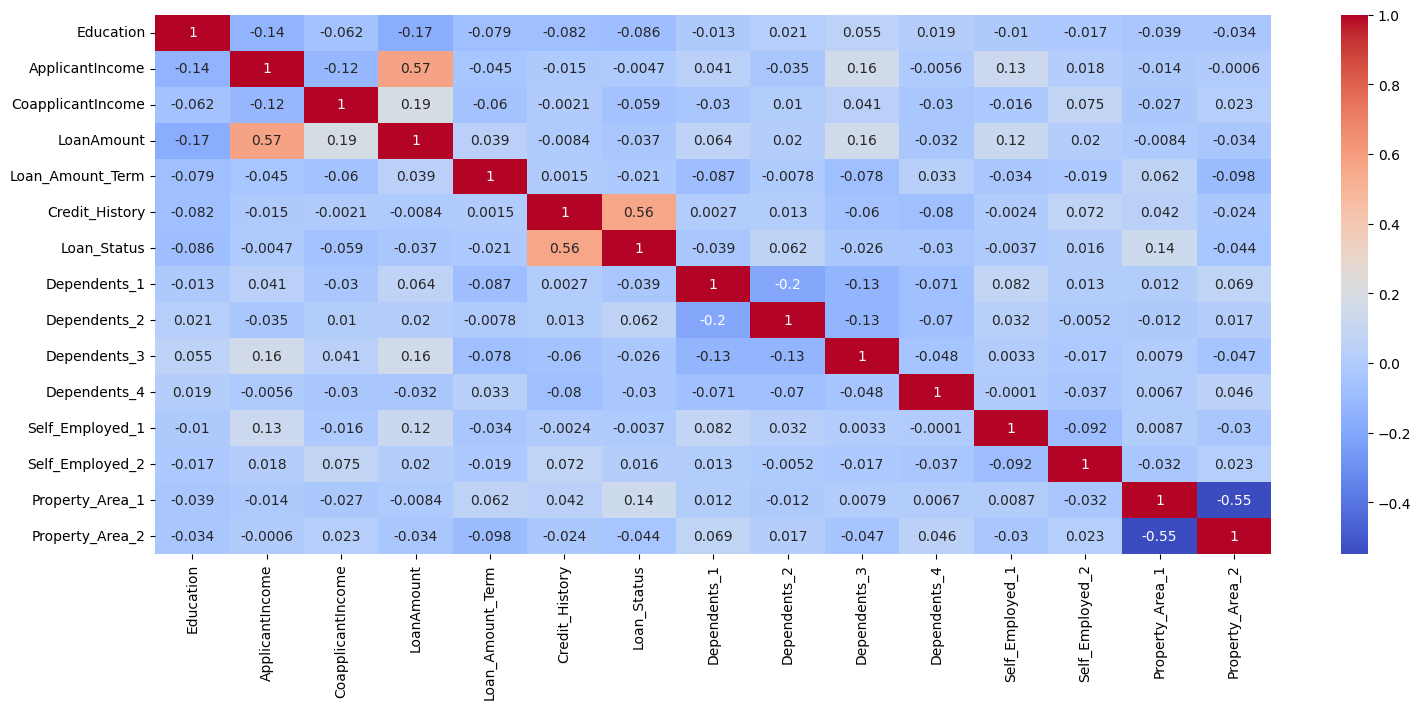

In [41]:
plt.figure(figsize=(18,7))
result=df.corr()
sns.heatmap(data=result,cmap="coolwarm",annot=True)
plt.show()

# **OUTLIER** **TREATMENT**

In [42]:
columns_selected=["LoanAmount","Loan_Amount_Term","Dependents_1","Dependents_3+",
                  "Dependents_nan","Self_Employed_Yes","Self_Employed_nan","Property_Area_Semiurban"]
df.drop(columns=columns_selected,inplace=True)

KeyError: "['Dependents_3+', 'Dependents_nan', 'Self_Employed_Yes', 'Self_Employed_nan', 'Property_Area_Semiurban'] not found in axis"

In [43]:
columns_selected = [
    "LoanAmount",
    "Loan_Amount_Term",
    "Dependents_1",
    "Dependents_3+",
    "Dependents_nan",
    "Self_Employed_Yes",
    "Self_Employed_nan",
    "Property_Area_Semiurban"
]

# Drop only columns that actually exist
existing_columns = [
    col for col in columns_selected
    if col in df.columns
]

print("Columns to drop:", existing_columns)

df.drop(columns=existing_columns, inplace=True)


Columns to drop: ['LoanAmount', 'Loan_Amount_Term', 'Dependents_1']


In [ ]:
df.head()

/tmp/ipykernel_1156/3676761541.py:7: UserWarning: Tight layout not applied. tight_layout cannot make Axes height small enough to accommodate all Axes decorations.
  plt.tight_layout()


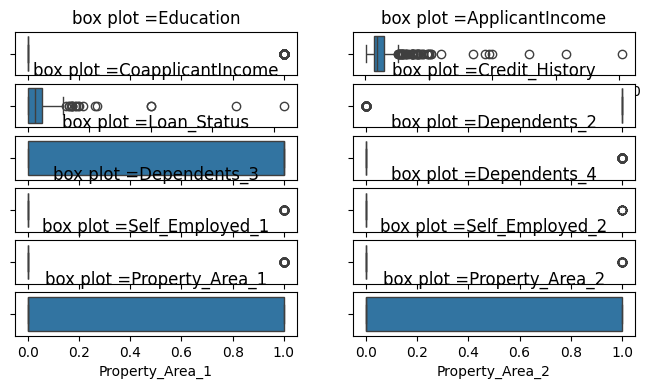

In [44]:
columns=df.columns
plt.figure(figsize=(8,8))
for i,col in enumerate(columns):
    plt.subplot(len(columns),2,i+1)
    sns.boxplot(x=df[col])
    plt.title(f"box plot ={col}")
plt.tight_layout()
plt.show()

In [45]:
df["ApplicantIncome"].describe()

,ApplicantIncome
count,614.000000
mean,5403.459283
std,6109.041673
min,150.000000
25%,2877.500000
50%,3812.500000
75%,5795.000000
max,81000.000000


In [46]:
columns = ['ApplicantIncome', 'Education', 'ApplicantIncome','Credit_History','Dependents_2']

for col in columns:
#find  first and third quantile
  q1=df[col].quantile(0.25)
  q3=df[col].quantile(0.75)
#find the iqr
  iqr=q3-q1
#find the upper and lower bound
  upper=q3+1.5*iqr
  lower=q1-1.5*iqr
  outlier = df[(df[col]< lower) | (df[col] >upper)]


In [47]:
outlier[col]

,Dependents_2
5,1.0
8,1.0
10,1.0
11,1.0
12,1.0
...,...
591,1.0
596,1.0
599,1.0
607,1.0


In [48]:
df[col]=df[col].clip(upper=upper,lower=lower)# to replace the value of outiler with the

there is no outliers in this code

In [49]:
X = df.drop("Loan_Status", axis=1)

y = df["Loan_Status"]

In [50]:
X_train, X_test , y_train , y_test=train_test_split(X,y,train_size=0.8,random_state=42)

#Feature Engineering and Target Seperation

In [51]:
df["TotalIncome"] = df["ApplicantIncome"] + df["CoapplicantIncome"]

In [54]:
# Separate features (X) and target (y)
X = df.drop(columns=["Loan_Status"], axis=1)
y = df["Loan_Status"]

# Convert remaining categorical columns into numerical columns
X = pd.get_dummies(X, drop_first=True, dtype=int)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (614, 12)
y shape: (614,)


In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (491, 12)
X_test shape: (123, 12)
y_train shape: (491,)
y_test shape: (123,)


In [56]:
print(y_train.value_counts())

Loan_Status
1    337
0    154
Name: count, dtype: int64


In [57]:
print(y_train.value_counts(normalize=True) * 100)

Loan_Status
1    68.635438
0    31.364562
Name: proportion, dtype: float64


In [58]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [59]:
imputer = SimpleImputer(strategy="median")

X_train = imputer.fit_transform(X_train)

X_test = imputer.transform(X_test)

print("Missing values handled")

Missing values handled


#Feature Scaling

In [60]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed")

Feature scaling completed


##SMOTE

In [61]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train_scaled,
    y_train
)

print("Before SMOTE:")
print(y_train.value_counts())

print("\nAfter SMOTE:")
print(y_train_smote.value_counts())

Before SMOTE:
Loan_Status
1    337
0    154
Name: count, dtype: int64

After SMOTE:
Loan_Status
1    337
0    337
Name: count, dtype: int64


In [64]:
# Decision Tree Classifier - Base Model

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Create the Decision Tree model
dt_model = DecisionTreeClassifier(random_state=42)

# Train the model using SMOTE training data
dt_model.fit(X_train_smote, y_train_smote)

# Predict using test data
y_pred_dt = dt_model.predict(X_test_scaled)

# Evaluate the model
print("Decision Tree Base Model Results")
print("--------------------------------")
print("Accuracy:", accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt, zero_division=0))

# Display confusion matrix
#ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt)
#plt.title("Decision Tree - Confusion Matrix")
#plt.show()


Decision Tree Base Model Results
--------------------------------
Accuracy: 0.6991869918699187

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.74      0.60        38
           1       0.85      0.68      0.76        85

    accuracy                           0.70       123
   macro avg       0.68      0.71      0.68       123
weighted avg       0.75      0.70      0.71       123

